In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load the Indian real estate dataset
df = pd.read_csv("../data/da_realestate_listings.csv")

# Convert listed_date into datetime format
df["listed_date"] = pd.to_datetime(df["listed_date"])

# Display dataset information
print("Dataset shape:", df.shape)
print("\nDataset columns:")
print(df.columns.tolist())

print("\nDate range:")
print(df["listed_date"].min(), "to", df["listed_date"].max())

print("\nMissing values:")
print(df.isnull().sum())

# Display first five records
df.head()

Dataset shape: (600, 15)

Dataset columns:
['listing_id', 'city', 'locality', 'type', 'area_sqft', 'price_per_sqft', 'total_price_lakh', 'age_years', 'floor', 'parking', 'furnished', 'listed_date', 'days_on_market', 'transaction_type', 'sold']

Date range:
2023-01-02 00:00:00 to 2024-12-30 00:00:00

Missing values:
listing_id          0
city                0
locality            0
type                0
area_sqft           0
price_per_sqft      0
total_price_lakh    0
age_years           0
floor               0
parking             0
furnished           0
listed_date         0
days_on_market      0
transaction_type    0
sold                0
dtype: int64


,listing_id,city,locality,type,area_sqft,price_per_sqft,total_price_lakh,age_years,floor,parking,furnished,listed_date,days_on_market,transaction_type,sold
0,PROP-0001,Chennai,CHE-Sector-18,4BHK,2507,13243,325.79,12,13,0,Unfurnished,2023-01-18,198,Rent,0
1,PROP-0002,Mumbai,MUM-Sector-5,Commercial,1404,7616,247.88,11,24,1,Fully,2023-07-30,123,Rent,0
2,PROP-0003,Delhi NCR,DEL-Sector-17,Plot,2673,3117,148.91,12,10,0,Fully,2023-05-05,164,Sale,0
3,PROP-0004,Pune,PUN-Sector-28,2BHK,1225,6940,108.03,11,20,0,Fully,2024-09-11,214,Sale,1
4,PROP-0005,Delhi NCR,DEL-Sector-3,Villa,2412,23280,363.66,16,4,1,Unfurnished,2023-05-23,171,Rent,1


In [3]:
# Group property listings by month
monthly_data = (
    df.set_index("listed_date")
      .resample("MS")["total_price_lakh"]
      .mean()
      .reset_index()
)

# Rename columns as required by Prophet
monthly_data.columns = ["ds", "y"]

# Display the prepared time series
print("Monthly observations:", len(monthly_data))

monthly_data.head(10)

Monthly observations: 24


,ds,y
0,2023-01-01,227.271034
1,2023-02-01,258.257500
2,2023-03-01,280.621667
3,2023-04-01,250.044783
4,2023-05-01,204.890000
5,2023-06-01,240.860000
6,2023-07-01,202.985556
7,2023-08-01,199.903571
8,2023-09-01,185.100417
9,2023-10-01,311.823750


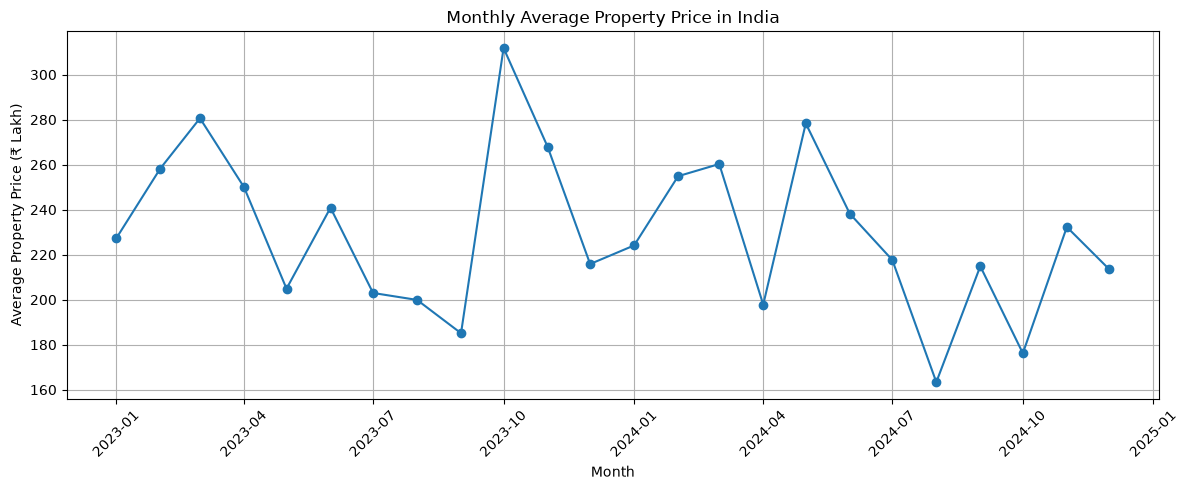

In [4]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_data["ds"],
    monthly_data["y"],
    marker="o"
)

plt.title("Monthly Average Property Price in India")
plt.xlabel("Month")
plt.ylabel("Average Property Price (₹ Lakh)")
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [5]:
# Split data chronologically
train = monthly_data.iloc[:-3].copy()
test = monthly_data.iloc[-3:].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train["ds"].min(), "to", train["ds"].max())

print("\nTesting period:")
print(test["ds"].min(), "to", test["ds"].max())

Training observations: 21
Testing observations: 3

Training period:
2023-01-01 00:00:00 to 2024-09-01 00:00:00

Testing period:
2024-10-01 00:00:00 to 2024-12-01 00:00:00


In [6]:
# Initialize Prophet
model = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=False,
    daily_seasonality=False,
    interval_width=0.95
)

# Train the model
model.fit(train)

print("Prophet model trained successfully!")

11:58:16 - cmdstanpy - INFO - Chain [1] start processing
11:58:16 - cmdstanpy - INFO - Chain [1] done processing


Prophet model trained successfully!


In [7]:
# Create future dates covering the test period and next 3 months
future = model.make_future_dataframe(
    periods=6,
    freq="MS"
)

# Generate predictions
forecast = model.predict(future)

# Display forecast columns
forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail(9)

,ds,yhat,yhat_lower,yhat_upper
18,2024-07-01,223.191380,154.310271,288.832985
19,2024-08-01,221.913915,157.599701,292.394389
20,2024-09-01,220.636449,150.544695,288.986967
21,2024-10-01,219.400192,151.522521,282.035998
22,2024-11-01,218.122727,154.669122,288.193920
23,2024-12-01,216.886470,148.829014,283.273671
24,2025-01-01,215.609005,148.100622,288.156236
25,2025-02-01,214.331539,144.674202,278.691302
26,2025-03-01,213.177700,145.383187,278.665069


In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Select predictions for the 3 test months
test_predictions = forecast[
    forecast["ds"].isin(test["ds"])
][["ds", "yhat"]]

# Match actual and predicted values
evaluation = test.merge(test_predictions, on="ds")

# Calculate errors
mae = mean_absolute_error(evaluation["y"], evaluation["yhat"])
rmse = np.sqrt(mean_squared_error(evaluation["y"], evaluation["yhat"]))

print(f"MAE: {mae:.2f} lakh")
print(f"RMSE: {rmse:.2f} lakh")

MAE: 20.28 lakh
RMSE: 26.32 lakh


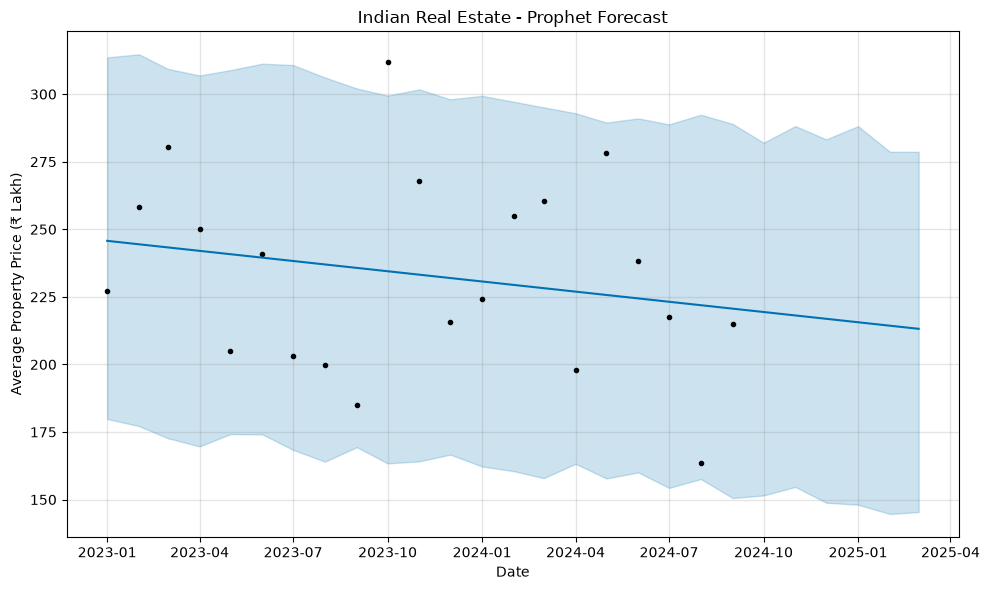

In [9]:
# Plot Prophet forecast
fig = model.plot(forecast)

plt.title("Indian Real Estate - Prophet Forecast")
plt.xlabel("Date")
plt.ylabel("Average Property Price (₹ Lakh)")
plt.tight_layout()

plt.show()

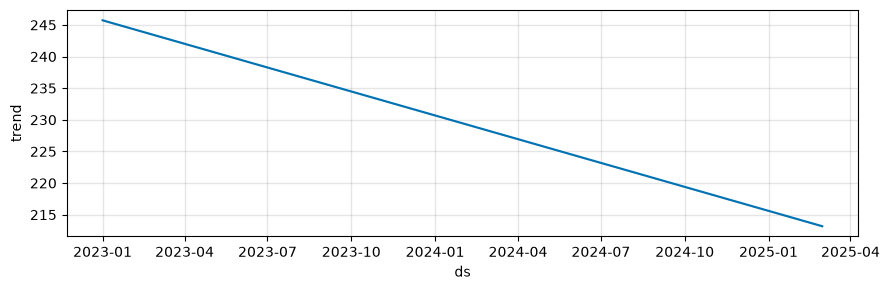

In [10]:
# Plot trend and seasonal components
fig = model.plot_components(forecast)

plt.tight_layout()
plt.show()

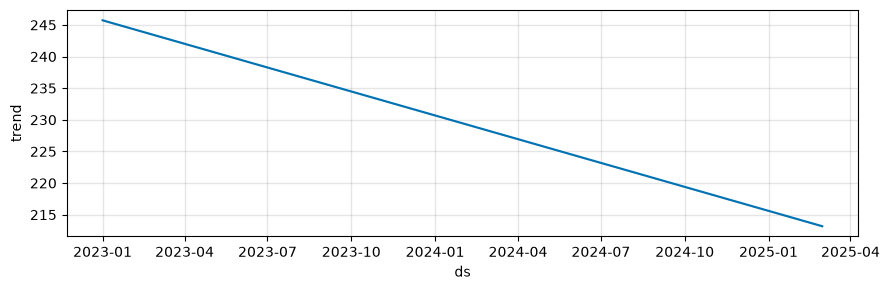

In [11]:
# Plot trend and seasonal components

fig = model.plot_components(forecast)

plt.tight_layout()
plt.show()

In [13]:
comparison = evaluation.copy()

comparison["error"] = comparison["y"] - comparison["yhat"]

comparison = comparison.rename(columns={
    "y": "Actual Price (Lakh)",
    "yhat": "Predicted Price (Lakh)"
})

display(comparison)

,ds,Actual Price (Lakh),Predicted Price (Lakh),error
0,2024-10-01,176.203000,219.400192,-43.197192
1,2024-11-01,232.295500,218.122727,14.172773
2,2024-12-01,213.428235,216.886470,-3.458235


In [14]:
from pathlib import Path

output_dir = Path("../outputs")
output_dir.mkdir(exist_ok=True)

forecast.to_csv(output_dir / "prophet_forecast.csv", index=False)
comparison.to_csv(output_dir / "forecast_evaluation.csv", index=False)

print("Forecast and evaluation files saved successfully.")

Forecast and evaluation files saved successfully.


In [15]:
# Save Prophet forecast chart
fig1 = model.plot(forecast)

fig1.savefig(
    "../outputs/prophet_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig1)

# Save forecast components chart
fig2 = model.plot_components(forecast)

fig2.savefig(
    "../outputs/forecast_components.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig2)

print("Both forecast charts saved successfully!")

Both forecast charts saved successfully!


## Business Insights

1. The dataset contains 600 Indian real estate listings covering January 2023 to December 2024.

2. Monthly average property prices fluctuate throughout the observation period.

3. The Prophet model achieved an MAE of ₹20.28 lakh and RMSE of ₹26.32 lakh on the three-month test period.

4. The model provides a baseline forecast, but its reliability is limited by the short historical dataset.

## Limitations

- Only 24 monthly observations are available.
- Evaluation uses only three test observations.
- Property prices vary by city, locality, property type and transaction type.
- Forecasts should not be treated as guaranteed market prices.